# Tugas CNN — Klasifikasi Penyakit Daun Tanaman (PlantVillage)

Nama: Dewi
Dataset: PlantVillage — https://www.kaggle.com/datasets/mohitsingh1804/plantvillage

## Tentang Dataset

PlantVillage itu dataset gambar daun tanaman yang dipakai buat deteksi penyakit tanaman dari foto, total aslinya ada 38 kelas (macam-macam tanaman x macam-macam penyakit/sehat). Untuk tugas ini aku ambil **5 kelas** aja biar fokus dan nggak kelamaan trainingnya:

1. **Apel - Apple Scab** (penyakit kudis pada daun apel)
2. **Apel - Sehat**
3. **Jagung - Karat Daun** (Common Rust)
4. **Kentang - Hawar Daun Akhir** (Late Blight)
5. **Tomat - Sehat**

Dipilih yang beda-beda jenis tanamannya (apel, jagung, kentang, tomat) plus ada yang sehat vs sakit, biar modelnya belajar bedain pola visual yang cukup beragam.

**Catatan soal sumber data:** dataset aslinya ada di Kaggle, tapi untuk download dari Kaggle butuh akun dan API key (`kaggle.json`) masing-masing orang, jadi kalau dipasang di notebook malah bikin orang lain nggak bisa langsung run. PlantVillage ini dataset publik dan ada mirror resminya di GitHub (dari salah satu pembuat datasetnya, isinya sama persis), jadi aku ambil dari situ pakai `git sparse-checkout` supaya cuma 5 kelas yang dipilih yang didownload (nggak perlu download semua ~54.000 gambar di 38 kelas).

## 1. Import Library

Library utama yang dipakai: **TensorFlow/Keras** buat bangun dan latih CNN-nya, **scikit-learn** buat confusion matrix & classification report, sama **matplotlib/seaborn** buat visualisasi.

In [1]:
import os
import shutil
import random
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import confusion_matrix, classification_report

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

sns.set_style("whitegrid")
print("TensorFlow version:", tf.__version__)


I0000 00:00:1791838337.685042    1240 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791838337.685669    1240 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791838337.737574    1240 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791838338.875059    1240 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791838338.875619    1240 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.21.0


## 2. Download Dataset

Cell di bawah ini ngecek dulu apakah folder `dataset/` udah ada isinya. Kalau belum, baru di-clone dari GitHub mirror PlantVillage-Dataset, tapi cuma 5 folder kelas yang dipilih aja (pakai `git sparse-checkout`) biar nggak download semua data yang nggak kepake.

In [ ]:
KELAS_TERPILIH = [
    "Apple___Apple_scab",
    "Apple___healthy",
    "Corn_(maize)___Common_rust_",
    "Potato___Late_blight",
    "Tomato___healthy",
]

DATASET_DIR = "dataset"

sudah_lengkap = os.path.isdir(DATASET_DIR) and all(
    os.path.isdir(os.path.join(DATASET_DIR, k)) for k in KELAS_TERPILIH
)

if not sudah_lengkap:
    print("Mengunduh 5 kelas dari mirror GitHub PlantVillage-Dataset...")
    if os.path.isdir("pv_repo"):
        shutil.rmtree("pv_repo")
    subprocess.run(["git", "clone", "--filter=blob:none", "--no-checkout", "--depth", "1",
                     "https://github.com/spMohanty/PlantVillage-Dataset.git", "pv_repo"], check=True)
    subprocess.run(["git", "-C", "pv_repo", "sparse-checkout", "init", "--cone"], check=True)
    subprocess.run(["git", "-C", "pv_repo", "sparse-checkout", "set"] +
                    [f"raw/color/{k}" for k in KELAS_TERPILIH], check=True)
    subprocess.run(["git", "-C", "pv_repo", "checkout"], check=True)
    os.makedirs(DATASET_DIR, exist_ok=True)
    for k in KELAS_TERPILIH:
        shutil.move(os.path.join("pv_repo", "raw", "color", k), os.path.join(DATASET_DIR, k))
    shutil.rmtree("pv_repo")
    print("Selesai download.")
else:
    print("Dataset sudah ada di folder 'dataset/', skip download.")

for k in KELAS_TERPILIH:
    jumlah = len(os.listdir(os.path.join(DATASET_DIR, k)))
    print(f"{k}: {jumlah} gambar")


Dataset sudah ada di folder 'dataset/', skip download.
Apple___Apple_scab: 630 gambar
Apple___healthy: 1645 gambar
Corn_(maize)___Common_rust_: 1192 gambar
Potato___Late_blight: 1000 gambar
Tomato___healthy: 1590 gambar


## 3. Jumlah Gambar per Kelas

Kriteria #2: nampilin grafik jumlah gambar di tiap kelas. Dari hasil di atas kelihatan jumlahnya nggak seimbang — ada yang cuma 630 gambar (Apple Scab), ada yang sampai 1645 gambar (Apel Sehat). Ini divisualisasikan pakai bar chart horizontal biar nama kelasnya kebaca jelas.

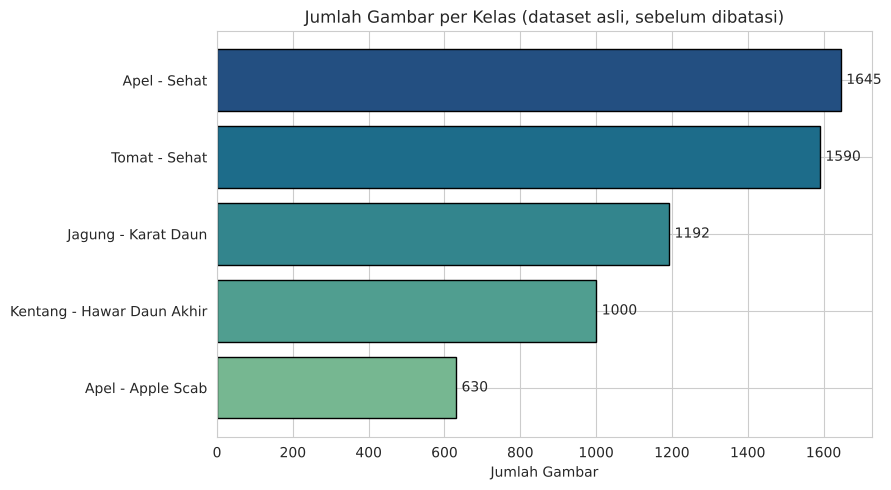

In [3]:
label_tampilan = {
    "Apple___Apple_scab": "Apel - Apple Scab",
    "Apple___healthy": "Apel - Sehat",
    "Corn_(maize)___Common_rust_": "Jagung - Karat Daun",
    "Potato___Late_blight": "Kentang - Hawar Daun Akhir",
    "Tomato___healthy": "Tomat - Sehat",
}

jumlah_per_kelas = {
    k: len(os.listdir(os.path.join(DATASET_DIR, k))) for k in KELAS_TERPILIH
}

df_jumlah = pd.DataFrame({
    "Kelas": [label_tampilan[k] for k in KELAS_TERPILIH],
    "Jumlah Gambar": [jumlah_per_kelas[k] for k in KELAS_TERPILIH],
}).sort_values("Jumlah Gambar", ascending=True)

plt.figure(figsize=(9, 5))
bars = plt.barh(df_jumlah["Kelas"], df_jumlah["Jumlah Gambar"],
                 color=sns.color_palette("crest", len(df_jumlah)), edgecolor="black")
for b in bars:
    w = b.get_width()
    plt.text(w + 15, b.get_y() + b.get_height()/2, str(w), va="center", fontsize=10)
plt.xlabel("Jumlah Gambar")
plt.title("Jumlah Gambar per Kelas (dataset asli, sebelum dibatasi)")
plt.tight_layout()
plt.show()


## 4. Contoh Gambar dari 5 Kelas

Kriteria #1: nampilin contoh data yang dimuat dari 5 kelas. Di bawah ini diambil 1 gambar acak dari tiap kelas buat dilihat bentuknya kayak gimana — kelihatan bedanya kalau daun yang sakit biasanya ada bercak/pola warna yang nggak rata dibanding yang sehat.

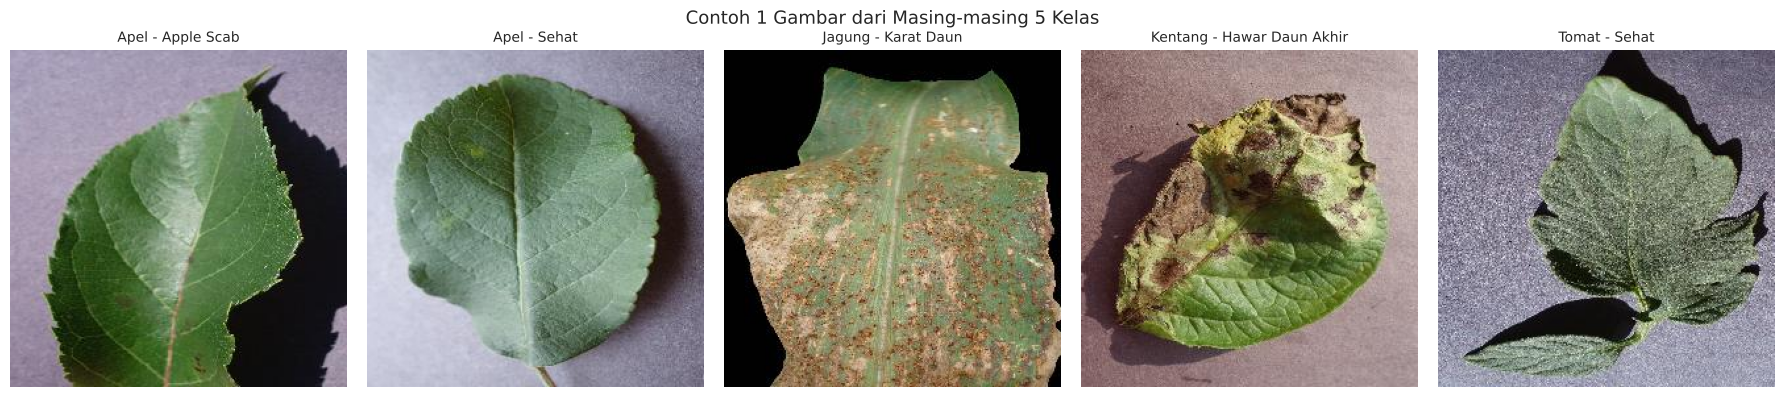

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, k in zip(axes, KELAS_TERPILIH):
    files = os.listdir(os.path.join(DATASET_DIR, k))
    contoh_file = os.path.join(DATASET_DIR, k, random.choice(files))
    img = tf.keras.utils.load_img(contoh_file)
    ax.imshow(img)
    ax.set_title(label_tampilan[k], fontsize=10)
    ax.axis("off")
plt.suptitle("Contoh 1 Gambar dari Masing-masing 5 Kelas", fontsize=13)
plt.tight_layout()
plt.show()


## 5. Membagi Dataset (Train/Validation/Test)

Karena jumlah gambar tiap kelas nggak seimbang dan supaya training-nya nggak kelamaan, tiap kelas dibatasi maksimal **350 gambar** (diambil acak dari masing-masing kelas), baru dibagi jadi:

- **70% Training** — buat melatih model
- **15% Validation** — buat mantau performa selama training (dipakai callback buat nentuin kapan berhenti)
- **15% Testing** — buat uji akhir pakai data yang sama sekali belum pernah dilihat model

File-file gambarnya disalin ke struktur folder `split/train/<kelas>`, `split/val/<kelas>`, `split/test/<kelas>`.

In [5]:
# Dataset aslinya jumlah gambar per kelas nggak seimbang (ada yang 630, ada yang 1645).
# Supaya training nggak condong ke kelas yang datanya lebih banyak, dan supaya waktu training
# nggak kelamaan, tiap kelas dibatasi maksimal 350 gambar (diambil acak), lalu dibagi
# 70% train, 15% validation, 15% testing.

N_PER_KELAS = 350
RASIO = {"train": 0.70, "val": 0.15, "test": 0.15}
SPLIT_DIR = "split"

if os.path.isdir(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)

ringkasan_split = []
for k in KELAS_TERPILIH:
    files = os.listdir(os.path.join(DATASET_DIR, k))
    random.shuffle(files)
    files = files[:N_PER_KELAS]
    n = len(files)
    n_train = int(n * RASIO["train"])
    n_val = int(n * RASIO["val"])
    bagian = {
        "train": files[:n_train],
        "val": files[n_train:n_train + n_val],
        "test": files[n_train + n_val:],
    }
    for nama_bagian, daftar_file in bagian.items():
        tujuan = os.path.join(SPLIT_DIR, nama_bagian, k)
        os.makedirs(tujuan, exist_ok=True)
        for f in daftar_file:
            shutil.copy(os.path.join(DATASET_DIR, k, f), os.path.join(tujuan, f))
    ringkasan_split.append({
        "Kelas": label_tampilan[k],
        "Train": len(bagian["train"]),
        "Validation": len(bagian["val"]),
        "Test": len(bagian["test"]),
    })

pd.DataFrame(ringkasan_split).set_index("Kelas")


,Train,Validation,Test
Kelas,,,
Apel - Apple Scab,244,52,54
Apel - Sehat,244,52,54
Jagung - Karat Daun,244,52,54
Kentang - Hawar Daun Akhir,244,52,54
Tomat - Sehat,244,52,54


## 6. Membuat Dataset Pipeline (tf.data)

Dari folder `split/` yang udah dibuat, dataset dimuat pakai `image_dataset_from_directory` yang otomatis ngelabelin gambar berdasarkan nama foldernya. Semua gambar di-resize ke 128x128 piksel biar ukurannya seragam (dataset aslinya udah 256x256, tapi dikecilin lagi biar training lebih cepat).

`.cache()`, `.shuffle()`, dan `.prefetch()` dipakai biar proses baca data nggak jadi bottleneck pas training (sesuai yang dijelasin di modul soal data pipeline).

In [6]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, "train"), image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=True, seed=RANDOM_STATE)
val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, "val"), image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=False)
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, "test"), image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=False)

nama_kelas = train_ds.class_names
print("Urutan kelas:", nama_kelas)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(500, seed=RANDOM_STATE).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)


Found 1220 files belonging to 5 classes.


Found 260 files belonging to 5 classes.


Found 270 files belonging to 5 classes.


Urutan kelas: ['Apple___Apple_scab', 'Apple___healthy', 'Corn_(maize)___Common_rust_', 'Potato___Late_blight', 'Tomato___healthy']


E0000 00:00:1791838340.392592    1240 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 7. Data Augmentation

Kriteria #3 (opsional): augmentasi data dan contoh hasilnya dari 5 kelas.

Augmentasi dipakai biar model nggak gampang hafalan (overfitting) ke posisi/orientasi gambar training, soalnya jumlah data training per kelas lumayan terbatas (cuma 244 gambar). Teknik yang dipakai: flip horizontal, rotasi acak, zoom acak, dan kontras acak — kombinasi transformasi geometris & ruang warna yang disebutkan juga di modul.

Di bawah ini ditampilkan 1 gambar asli dari tiap kelas beserta 3 versi hasil augmentasinya, biar kelihatan bedanya.

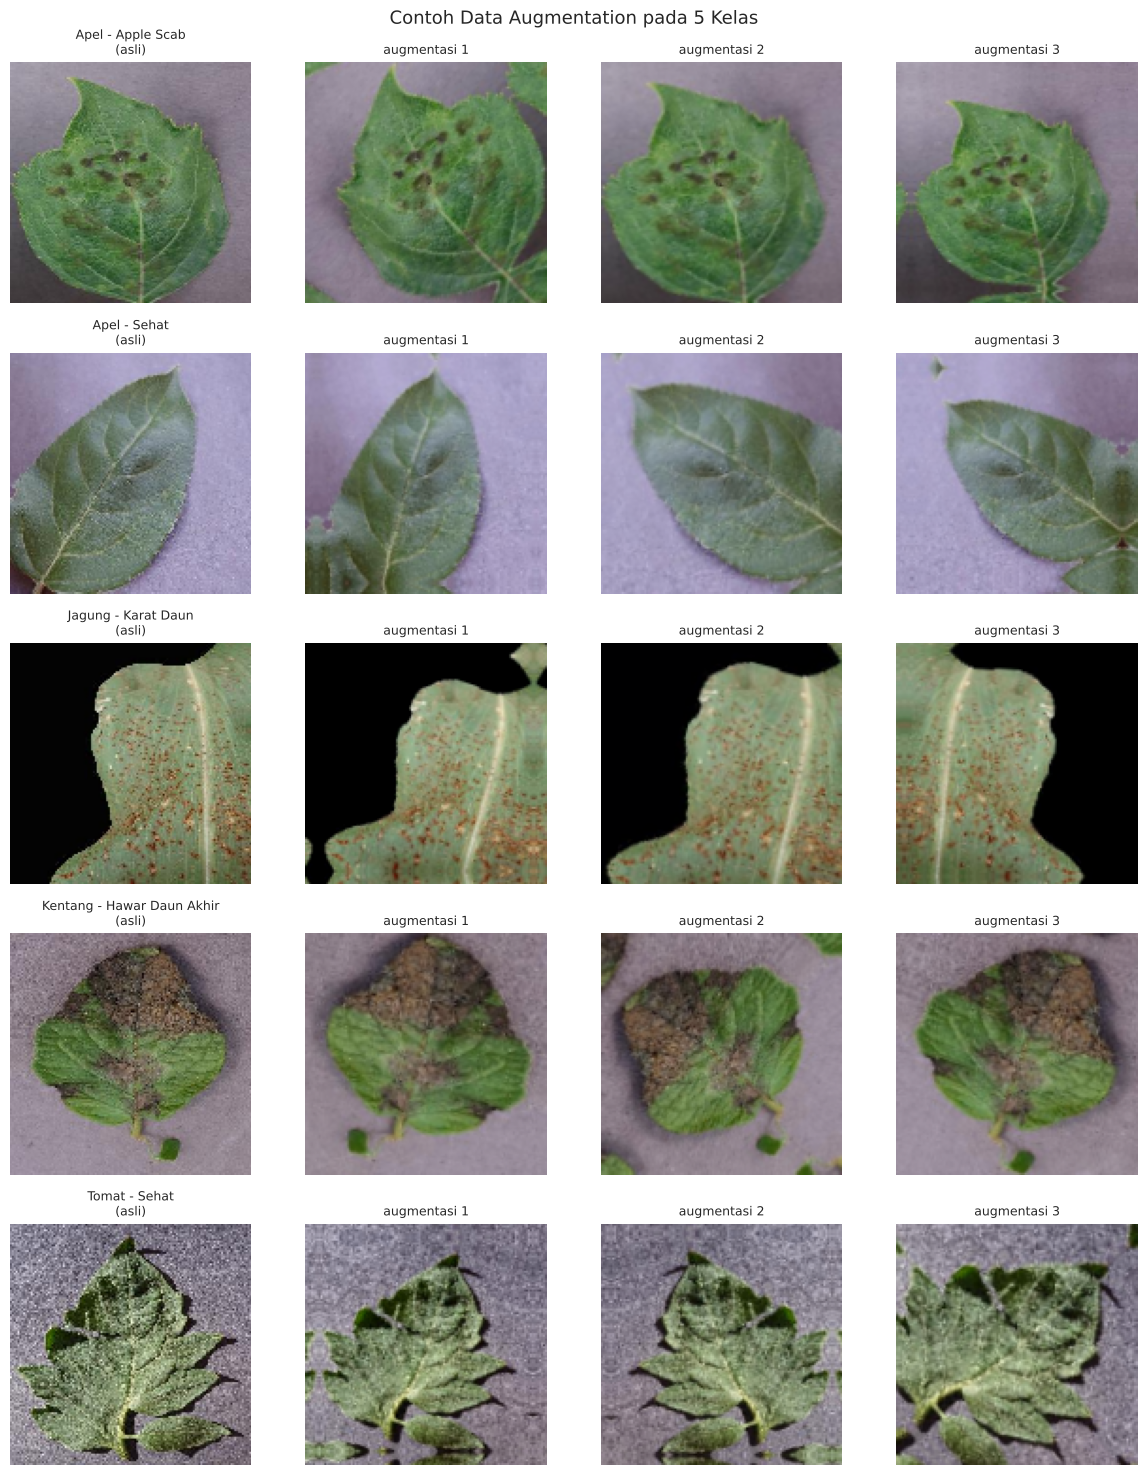

In [7]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="augmentasi")

# ambil 1 gambar contoh dari tiap kelas langsung dari folder train, lalu tampilkan
# versi asli vs 3 versi hasil augmentasi di sampingnya
fig, axes = plt.subplots(5, 4, figsize=(12, 15))
for i, k in enumerate(KELAS_TERPILIH):
    folder_train = os.path.join(SPLIT_DIR, "train", k)
    contoh_file = os.path.join(folder_train, os.listdir(folder_train)[0])
    img = tf.keras.utils.load_img(contoh_file, target_size=IMG_SIZE)
    img_arr = tf.keras.utils.img_to_array(img)
    img_batch = tf.expand_dims(img_arr, 0)

    axes[i, 0].imshow(img_arr.astype("uint8"))
    axes[i, 0].set_title(f"{label_tampilan[k]}\n(asli)", fontsize=9)
    axes[i, 0].axis("off")

    for j in range(1, 4):
        hasil_aug = data_augmentation(img_batch, training=True)
        axes[i, j].imshow(hasil_aug[0].numpy().astype("uint8"))
        axes[i, j].set_title(f"augmentasi {j}", fontsize=9)
        axes[i, j].axis("off")

plt.suptitle("Contoh Data Augmentation pada 5 Kelas", fontsize=13)
plt.tight_layout()
plt.show()


## 8. Membangun CNN Custom

Kriteria #4: aku pilih bikin **CNN custom dari nol** (bukan transfer learning) biar bisa lihat langsung gimana tiap komponen CNN (convolution, pooling, dense) bekerja sesuai yang dijelasin di modul, dan karena 5 kelas yang dipilih ini pola visualnya cukup beda-beda jadi model yang nggak terlalu besar juga udah bisa belajar dengan baik.

Arsitekturnya:
- Layer augmentasi (cuma aktif pas training) dan `Rescaling` buat normalisasi piksel dari 0-255 ke 0-1.
- 3 blok **Conv2D + MaxPooling2D** dengan jumlah filter yang makin banyak (32 → 64 → 128), tiap blok nge-ekstrak pola yang makin kompleks sambil ngecilin ukuran gambar.
- `Flatten` buat ngubah hasil ekstraksi fitur jadi vektor 1 dimensi, sebelum masuk ke `Dense` layer (Fully-Connected Layer).
- `Dropout(0.4)` buat nyegah overfitting dengan mematikan 40% neuron secara acak tiap training step.
- Output layer `Dense` dengan aktivasi **softmax** sejumlah 5 neuron (sesuai jumlah kelas), karena ini kasus klasifikasi multi-kelas.

Loss function pakai `categorical_crossentropy` (karena targetnya di-encode one-hot lewat `label_mode="categorical"`), optimizer pakai `adam`.

In [8]:
model = models.Sequential([
    tf.keras.Input(shape=IMG_SIZE + (3,)),
    data_augmentation,                 # cuma aktif saat training
    layers.Rescaling(1. / 255),        # normalisasi piksel 0-255 -> 0-1

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(len(nama_kelas), activation="softmax"),
], name="cnn_custom_plantvillage")

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "cnn_custom_plantvillage"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentasi (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

## 9. Callbacks

Kriteria #5: pakai callback biar training otomatis berhenti kalau udah nggak ada perkembangan.

- **EarlyStopping**: mantau `val_loss`, kalau nggak membaik selama 5 epoch berturut-turut, training dihentikan otomatis dan bobot model dikembalikan ke kondisi terbaik (`restore_best_weights=True`) — biar nggak kebawa ke epoch-epoch yang udah mulai overfitting.
- **ReduceLROnPlateau**: kalau `val_loss` stuck selama 2 epoch, learning rate otomatis diperkecil (dikali 0.5) biar model bisa "mengatur langkah" lebih halus pas udah mendekati titik optimal.

Model dilatih maksimal 25 epoch, tapi karena ada EarlyStopping, kemungkinan bakal berhenti lebih cepat.

In [9]:
early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
)

EPOCHS = 25

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop, reduce_lr],
    verbose=2,
)


Epoch 1/25


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


39/39 - 12s - 311ms/step - accuracy: 0.3951 - loss: 1.3743 - val_accuracy: 0.5231 - val_loss: 1.0584 - learning_rate: 0.0010


Epoch 2/25


39/39 - 10s - 260ms/step - accuracy: 0.5754 - loss: 0.9864 - val_accuracy: 0.5962 - val_loss: 1.0929 - learning_rate: 0.0010


...

39/39 - 20s - 501ms/step - accuracy: 0.9418 - loss: 0.1682 - val_accuracy: 0.8808 - val_loss: 0.3259 - learning_rate: 3.1250e-05


Epoch 22/25


39/39 - 10s - 260ms/step - accuracy: 0.9418 - loss: 0.1630 - val_accuracy: 0.8731 - val_loss: 0.3518 - learning_rate: 3.1250e-05


Epoch 23/25


39/39 - 10s - 253ms/step - accuracy: 0.9434 - loss: 0.1706 - val_accuracy: 0.8615 - val_loss: 0.3768 - learning_rate: 1.5625e-05


## 10. Grafik Histori Pelatihan

Kriteria #6: grafik akurasi dan loss selama training.

Training berhenti di epoch ke-23 dari maksimal 25 (EarlyStopping aktif kalau val_loss nggak membaik selama 5 epoch berturut-turut).


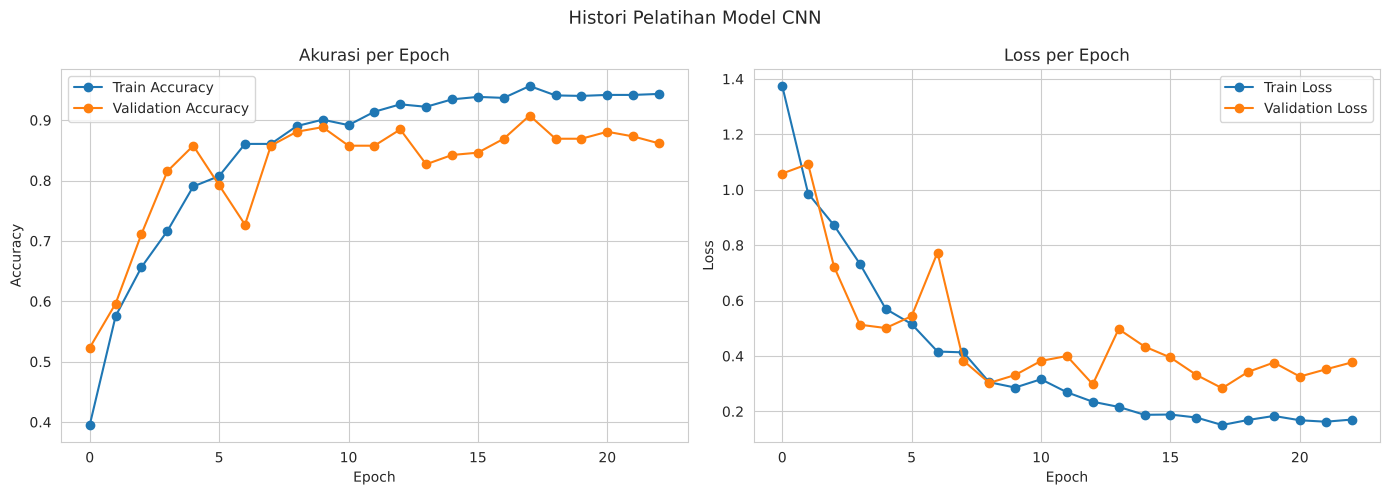

In [10]:
hist_df = pd.DataFrame(history.history)
epoch_terhenti = len(hist_df)
print(f"Training berhenti di epoch ke-{epoch_terhenti} dari maksimal {EPOCHS} "
      f"(EarlyStopping aktif kalau val_loss nggak membaik selama 5 epoch berturut-turut).")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(hist_df["accuracy"], marker="o", label="Train Accuracy")
axes[0].plot(hist_df["val_accuracy"], marker="o", label="Validation Accuracy")
axes[0].set_title("Akurasi per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(hist_df["loss"], marker="o", label="Train Loss")
axes[1].plot(hist_df["val_loss"], marker="o", label="Validation Loss")
axes[1].set_title("Loss per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.suptitle("Histori Pelatihan Model CNN", fontsize=13)
plt.tight_layout()
plt.show()


Dari grafik di atas kelihatan akurasi training terus naik sampai di atas 90%, sedangkan akurasi validation naik tapi lebih fluktuatif dan sempat stagnan di beberapa epoch — makanya `ReduceLROnPlateau` kepicu dan learning rate diperkecil bertahap. Training berhenti otomatis sebelum mencapai epoch maksimal karena `val_loss` udah nggak membaik lagi (EarlyStopping kepicu), tandanya model mulai mendekati titik dimana nambah epoch lagi cuma bikin overfitting, bukan nambah performa.

## 11. Evaluasi pada Data Testing

In [11]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Akurasi pada data testing : {test_acc:.3f}")
print(f"Loss pada data testing    : {test_loss:.3f}")


Akurasi pada data testing : 0.885
Loss pada data testing    : 0.320


## 12. Confusion Matrix

Kriteria #7: evaluasi pakai confusion matrix dan classification report.

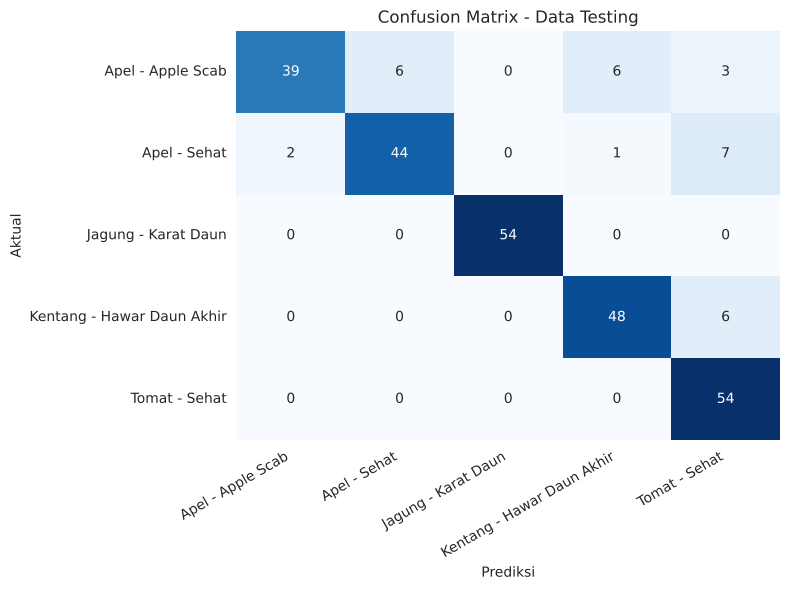

In [12]:
y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds])
y_pred_proba = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_pred_proba, axis=1)

cm = confusion_matrix(y_true, y_pred)
label_pendek = [label_tampilan[k] for k in nama_kelas]

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=label_pendek, yticklabels=label_pendek)
plt.title("Confusion Matrix - Data Testing")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [13]:
print(classification_report(y_true, y_pred, target_names=label_pendek))


                            precision    recall  f1-score   support

         Apel - Apple Scab       0.95      0.72      0.82        54
              Apel - Sehat       0.88      0.81      0.85        54
       Jagung - Karat Daun       1.00      1.00      1.00        54
Kentang - Hawar Daun Akhir       0.87      0.89      0.88        54
             Tomat - Sehat       0.77      1.00      0.87        54

                  accuracy                           0.89       270
                 macro avg       0.90      0.89      0.88       270
              weighted avg       0.90      0.89      0.88       270



**Baca hasil evaluasinya:**

- Kelas **Jagung - Karat Daun** diprediksi sempurna (precision & recall 1.00) — wajar karena pola karat daun jagung emang kelihatan paling khas/beda dibanding 4 kelas lainnya.
- Kelas **Apel - Apple Scab** punya recall paling rendah (0.72) — dari confusion matrix kelihatan 6 gambar Apple Scab salah diprediksi jadi Apel Sehat, dan 6 lagi jadi Kentang Hawar Daun. Ini masuk akal karena bercak kudis yang ringan kadang nggak terlalu mencolok jadi mirip sama daun sehat atau bercak penyakit lain.
- Kelas **Tomat - Sehat** punya recall sempurna (1.00) tapi precision paling rendah (0.77) — artinya model agak "kebanyakan" nebak Tomat Sehat buat gambar-gambar yang sebenarnya dari kelas lain (ada beberapa gambar Apel Scab, Apel Sehat, dan Kentang yang keprediksi jadi Tomat Sehat). Kemungkinan karena daun sehat dari tanaman manapun punya warna hijau yang relatif seragam sehingga lebih gampang disalahartikan satu sama lain oleh model yang masih sederhana ini.
- Secara keseluruhan akurasi di data testing sekitar **88-89%**, lumayan bagus untuk CNN custom yang dilatih dari nol dengan data terbatas (hanya ~244 gambar per kelas) tanpa transfer learning.

## 13. Contoh Prediksi Model

Sebagai eksplorasi tambahan, berikut beberapa contoh gambar dari data testing beserta label aktual vs prediksi model — termasuk beberapa contoh yang salah diprediksi, biar kelihatan jenis kesalahan yang dibuat model.

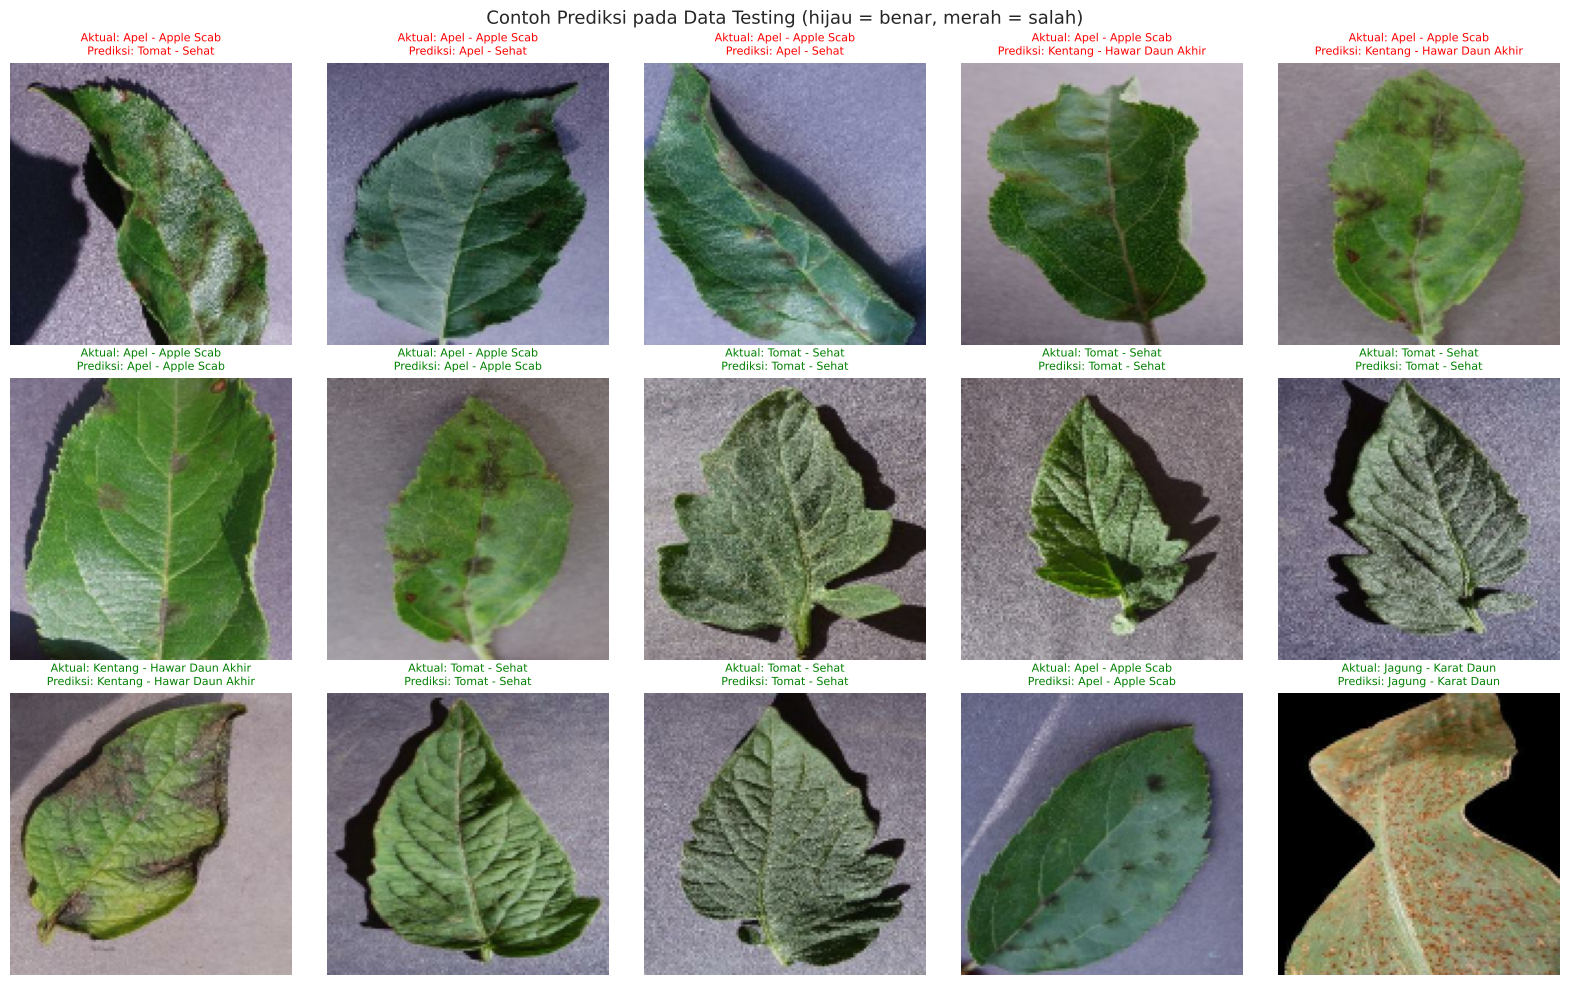

In [14]:
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
idx_salah = np.where(y_pred != y_true)[0]
idx_benar = np.where(y_pred == y_true)[0]
idx_tampil = list(idx_salah[:5]) + list(np.random.choice(idx_benar, min(10, len(idx_benar)), replace=False))

semua_gambar = np.concatenate([x.numpy() for x, _ in test_ds])

for ax, idx in zip(axes.flat, idx_tampil[:15]):
    ax.imshow(semua_gambar[idx].astype("uint8"))
    benar = y_pred[idx] == y_true[idx]
    warna = "green" if benar else "red"
    ax.set_title(f"Aktual: {label_pendek[y_true[idx]]}\nPrediksi: {label_pendek[y_pred[idx]]}",
                 fontsize=8, color=warna)
    ax.axis("off")

plt.suptitle("Contoh Prediksi pada Data Testing (hijau = benar, merah = salah)", fontsize=13)
plt.tight_layout()
plt.show()


## 14. Kesimpulan

- Model CNN custom (3 blok Conv2D + MaxPooling, dilatih dari nol tanpa transfer learning) berhasil mengklasifikasikan 5 kelas penyakit/kondisi daun tanaman dari dataset PlantVillage dengan **akurasi testing sekitar 88-89%**.
- Data augmentation (flip, rotasi, zoom, kontras) dipakai buat ngebantu model lebih general mengingat data training per kelas cuma sekitar 244 gambar.
- Callback `EarlyStopping` + `ReduceLROnPlateau` berhasil nyetop training otomatis begitu `val_loss` berhenti membaik, jadi nggak perlu nebak-nebak jumlah epoch yang pas secara manual.
- Dari confusion matrix, kesalahan model kebanyakan terjadi antar kelas yang pola visualnya emang mirip (misalnya Apple Scab vs Apel Sehat, atau kelas-kelas "sehat" yang warnanya cenderung seragam hijau), sementara kelas dengan pola khas kayak Jagung Karat Daun diprediksi sempurna.
- Buat pengembangan lebih lanjut, performa model kemungkinan bisa ditingkatkan lagi dengan transfer learning (misalnya pakai MobileNetV2 dengan bobot ImageNet), menambah jumlah data training per kelas, atau memperdalam arsitektur CNN-nya.